# 01. 데이터 파악

- **목적**: 서울시 상권분석서비스 3종(추정매출, 점포, 영역) 구조 파악, 분석 전 주의점과 전처리 항목 정리
- **데이터 출처** (`data/raw/`, cp949)
  - `서울시_상권분석서비스(추정매출-상권)_*.csv` 5개 (연도별)
  - `서울시_상권분석서비스(점포-상권)_*.csv` 5개 (연도별)
  - `서울시_상권분석서비스(영역-상권).csv`
  - 기간: 2021년 1분기 ~ 2026년 2분기 (22개 분기)
- **작성일**: 2026-10-16 (출력은 2026-10-15 실행 결과)
- 금액(`당월_매출_금액`)·건수(`당월_매출_건수`)는 해당 분기의 월평균 (원천부서 확인)

## 결론 요약
- 매출이 있는 상권의 최소 카페 수는 22개 분기 모두 3개 → 카페 1~2개 상권(2026년 2분기 286곳)은 매출 비공개, 분석 범위에서 빠짐
- 서울 카페 손님은 2분기에 전 분기 대비 +18.6%, 1분기에 −6.8% (분기별 중앙값) → 비교는 4개 분기 합계끼리 또는 전년 같은 분기끼리 해야 함
- 한 분기 만에 손님이 2배 넘게 뛰는 상권이 매 분기 존재 (2021년 2분기 52곳, 2026년 2분기 26곳) → 추천 단계에서 단절 상권 제외 필요
- 깨진 이름·컬럼명, 2025년부터 바뀐 점포 컬럼명, float 금액 컬럼 22개 확인 → `02_전처리`에서 처리

## 설정

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append("..")  # notebooks/에서 실행하므로 프로젝트 루트의 src를 import 경로에 추가
from src.data_io import CODE_DTYPES, load_yearly_csv
from src.viz import quarter_label, set_korean_font

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 60)
set_korean_font()

In [2]:
RAW_DIR = Path("../data/raw")
AREA_FILE = "서울시_상권분석서비스(영역-상권).csv"

CAFE_CODE = "CS100010"  # 서비스_업종_코드: 커피-음료
KEY_COLS = ["기준_년분기_코드", "상권_코드", "서비스_업종_코드"]
STORE_RENAME = {"점포_수": "일반_점포_수", "유사_업종_점포_수": "전체_점포_수"}  # 2025년 파일부터 새 이름 사용

LATEST_QUARTER = "20262"
STORE_BINS = [0, 2, 9, 1000]  # 1000: 상권 최대 카페 수보다 충분히 큰 상한
STORE_BIN_LABELS = ["1~2개", "3~9개", "10개 이상"]

JUMP_RATIO = 1.0   # 전 분기 대비 +100% 초과 = 2배 넘게 뜀
DROP_RATIO = -0.5  # 전 분기 대비 −50% 미만 = 절반 아래로 떨어짐
BREAK_EXAMPLE_CODE = "3110902"  # 사당역 4번
BREAK_EXAMPLE_QUARTERS = ("20231", "20244")

## 데이터 로드와 검증

- 연도별로 나뉜 파일을 합쳐 매출·점포·영역 3개 테이블 생성
- 점포 컬럼명이 2025년부터 바뀌어 새 이름으로 통일 (같은 정의인지는 1절에서 검증)

In [3]:
raw_sales = load_yearly_csv(RAW_DIR, "*추정매출*.csv")
raw_store = load_yearly_csv(RAW_DIR, "*점포-상권*.csv", rename_cols=STORE_RENAME)
raw_area = pd.read_csv(RAW_DIR / AREA_FILE, encoding="cp949", dtype=CODE_DTYPES)

서울시_상권분석서비스(추정매출-상권)_2021년.csv (89150, 55)


서울시_상권분석서비스(추정매출-상권)_2022년.csv (88834, 55)


서울시_상권분석서비스(추정매출-상권)_2023년.csv (88246, 55)


서울시_상권분석서비스(추정매출-상권)_2024년.csv (87179, 55)


서울시_상권분석서비스(추정매출-상권)_2025~2026년.csv (128053, 55)


서울시_상권분석서비스(점포-상권)_2021년.csv (303880, 14)


서울시_상권분석서비스(점포-상권)_2022년.csv (305587, 14)


서울시_상권분석서비스(점포-상권)_2023년.csv (307741, 14)


서울시_상권분석서비스(점포-상권)_2024년.csv (306889, 14)


서울시_상권분석서비스(점포-상권)_2025~2026년.csv (456659, 14)


In [4]:
# 키가 유일해야 이후 pivot·merge에서 행이 복제되지 않음
assert not raw_sales.duplicated(KEY_COLS).any()
assert not raw_store.duplicated(KEY_COLS).any()
assert raw_area["상권_코드"].is_unique

## 1. 파일 구조

- 테이블별 규모(행·열·분기·상권·업종 수)와 키 중복·결측 여부를 한 표로 확인

In [5]:
file_summary = pd.DataFrame({
    "행": [len(raw_sales), len(raw_store), len(raw_area)],
    "열": [raw_sales.shape[1], raw_store.shape[1], raw_area.shape[1]],
    "분기 수": [raw_sales["기준_년분기_코드"].nunique(), raw_store["기준_년분기_코드"].nunique(), np.nan],
    "상권 수": [raw_sales["상권_코드"].nunique(), raw_store["상권_코드"].nunique(), raw_area["상권_코드"].nunique()],
    "업종 수": [raw_sales["서비스_업종_코드"].nunique(), raw_store["서비스_업종_코드"].nunique(), np.nan],
    "키 중복": [raw_sales.duplicated(KEY_COLS).sum(), raw_store.duplicated(KEY_COLS).sum(),
              raw_area.duplicated("상권_코드").sum()],
    "빈 값": [raw_sales.isna().sum().sum(), raw_store.isna().sum().sum(), raw_area.isna().sum().sum()],
}, index=["추정매출", "점포", "영역"])
file_summary

,행,열,분기 수,상권 수,업종 수,키 중복,빈 값
추정매출,481462,55,22.0,1598,63.0,0,0
점포,1680756,14,22.0,1650,100.0,0,0
영역,1650,11,NaN,1650,NaN,0,0


### 관찰
- 추정매출 481,462행 × 55열, 점포 1,680,756행 × 14열, 영역 1,650행 × 11열
- 분기는 매출·점포 모두 22개, 상권은 매출 1,598개 / 점포 1,650개 / 영역 1,650개
- 업종은 매출 63개, 점포 100개 → 매출은 일부 업종만 공개
- 세 테이블 모두 키 중복 0건, 결측 0건 확인

In [6]:
print("분기:", raw_sales["기준_년분기_코드"].min(), "~", raw_sales["기준_년분기_코드"].max())

# 2025년 전후 점포 컬럼을 같은 이름으로 합쳤으므로, 정의가 같다면 모든 행에서 이 식이 성립해야 함
store_sum_mismatch = raw_store["일반_점포_수"] + raw_store["프랜차이즈_점포_수"] != raw_store["전체_점포_수"]
print("일반 + 프랜차이즈 ≠ 전체인 행:", int(store_sum_mismatch.sum()))

area_codes = set(raw_area["상권_코드"])
print("영역에 없는 상권: 매출", len(set(raw_sales["상권_코드"]) - area_codes),
      "/ 점포", len(set(raw_store["상권_코드"]) - area_codes))

분기: 20211 ~ 20262
일반 + 프랜차이즈 ≠ 전체인 행: 0
영역에 없는 상권: 매출 0 / 점포 0


In [7]:
raw_area["상권_구분_코드_명"].value_counts()

상권_구분_코드_명
골목상권    1090
전통시장     305
발달상권     249
관광특구       6
Name: count, dtype: int64

### 관찰
- 기간 20211 ~ 20262 확인
- 일반 + 프랜차이즈 ≠ 전체인 행 0건 → 2025년 전후 점포 컬럼은 같은 정의로 판단, 이름 통일 문제없음
- 매출·점포의 상권이 모두 영역 테이블에 있음 → 상권 코드로 연결 가능
- 상권 유형: 골목상권 1,090, 전통시장 305, 발달상권 249, 관광특구 6

## 2. 커피-음료 업종

- 2호점 대상이 카페이므로 업종 코드 `CS100010`(커피-음료)만 사용
- 분기별로 매출이 공개된 상권 수와 카페가 있는 상권 수를 비교해 매출 공개 범위 확인

In [8]:
print(raw_sales.loc[raw_sales["서비스_업종_코드"] == CAFE_CODE, "서비스_업종_코드_명"].unique())

cafe_sales = raw_sales.loc[lambda d: d["서비스_업종_코드"] == CAFE_CODE]
cafe_store = raw_store.loc[lambda d: d["서비스_업종_코드"] == CAFE_CODE]
print("커피 매출", len(cafe_sales), "행 / 커피 점포", len(cafe_store), "행")

['커피-음료']


커피 매출 23700 행 / 커피 점포 33263 행


In [9]:
open_cafe_store = cafe_store.loc[lambda d: d["전체_점포_수"] > 0]

quarter_coverage = pd.DataFrame({
    "매출이 있는 상권": cafe_sales.groupby("기준_년분기_코드")["상권_코드"].nunique(),
    "점포가 있는 상권": open_cafe_store.groupby("기준_년분기_코드")["상권_코드"].nunique(),
    "서울 카페 점포 수": cafe_store.groupby("기준_년분기_코드")["전체_점포_수"].sum(),
})
quarter_coverage.T

기준_년분기_코드,20211,20212,20213,20214,20221,20222,20223,20224,20231,20232,...,20241,20242,20243,20244,20251,20252,20253,20254,20261,20262
매출이 있는 상권,1047,1057,1067,1072,1070,1073,1083,1092,1085,1097,...,1087,1084,1088,1089,1077,1073,1077,1069,1064,1064
점포가 있는 상권,1480,1485,1493,1496,1496,1503,1504,1504,1503,1507,...,1519,1524,1523,1523,1521,1515,1515,1516,1512,1509
서울 카페 점포 수,19569,20017,20394,21014,21356,22057,22228,22918,22983,23266,...,23450,23409,23232,23042,22834,22707,22505,22356,22233,22229


### 관찰
- 카페가 있는데 매출이 없는 상권: 2021년 1분기 433곳(1,480 vs 1,047), 2026년 2분기 445곳(1,509 vs 1,064)
- 서울 카페 점포 수: 2021년 1분기 19,569개 → 2024년 1분기 23,450개 → 2026년 2분기 22,229개 (2024년 1분기 대비 −5.2%)
- 다음 단계: 카페가 있는데 매출이 없는 이유 확인 필요 (3절)

## 3. 매출이 공개되는 조건

- 2절에서 본 "카페는 있는데 매출이 없는 상권"의 원인 확인
- 점포 테이블에 매출을 붙여 매출 유무와 카페 수의 관계 확인

In [10]:
store_with_sales = cafe_store.merge(
    cafe_sales[["기준_년분기_코드", "상권_코드", "당월_매출_금액"]],
    on=["기준_년분기_코드", "상권_코드"], how="left", validate="one_to_one",
)
assert len(store_with_sales) == len(cafe_store)  # left join으로 점포 행이 늘면 이후 비율이 틀어짐

min_store_with_sales = (
    store_with_sales.loc[lambda d: d["당월_매출_금액"].notna()]
    .groupby("기준_년분기_코드")["전체_점포_수"]
    .min()
)
print("매출이 있는 상권의 최소 점포 수(분기별):", sorted(min_store_with_sales.unique()))

매출이 있는 상권의 최소 점포 수(분기별): [np.int64(3)]


In [11]:
latest_store = store_with_sales.loc[
    lambda d: (d["기준_년분기_코드"] == LATEST_QUARTER) & (d["전체_점포_수"] > 0)
]
pd.crosstab(
    pd.cut(latest_store["전체_점포_수"], STORE_BINS, labels=STORE_BIN_LABELS),
    latest_store["당월_매출_금액"].notna().map({True: "매출 있음", False: "매출 없음"}),
)

당월_매출_금액,매출 없음,매출 있음
전체_점포_수,,
1~2개,286,0
3~9개,142,490
10개 이상,17,574


### 관찰
- 22개 분기 모두 매출이 있는 상권의 최소 카페 수가 정확히 3개 → 카페 1~2개 상권은 매출 비공개로 판단
- 2026년 2분기 카페 1~2개 상권 286곳은 전부 매출 없음
- 카페 3~9개 상권도 142곳(22.5%), 10개 이상 상권도 17곳(2.9%) 매출 없음 → 원인은 공개되지 않음, 한계로 기록 필요
- 이 분석은 매출이 공개된 상권 안에서의 추천으로 범위 한정

## 4. 서울 전체 카페 손님의 계절성

- 분기 비교 기준(바로 앞 분기 vs 전년 같은 분기)을 정하기 위해 서울 전체 계절 패턴 확인
- 상권이 새로 생기거나 빠지는 효과를 없애려고 22개 분기 모두 매출이 있는 상권만 합산

In [12]:
quarterly_counts = cafe_sales.pivot(index="상권_코드", columns="기준_년분기_코드", values="당월_매출_건수")
full_period_codes = quarterly_counts.dropna().index

seoul_counts = (
    quarterly_counts.loc[full_period_codes]
    .sum()
    .div(1e4)
    .to_frame("건수(만 건)")
    .assign(**{
        "전 분기 대비(%)": lambda d: d["건수(만 건)"].pct_change() * 100,
        "전년 같은 분기 대비(%)": lambda d: d["건수(만 건)"].pct_change(4) * 100,
    })
)
print(len(full_period_codes), "개 상권 합계")
seoul_counts.round(1).T

916 개 상권 합계


기준_년분기_코드,20211,20212,20213,20214,20221,20222,20223,20224,20231,20232,...,20241,20242,20243,20244,20251,20252,20253,20254,20261,20262
건수(만 건),6176.0,8190.3,8061.7,8151.6,7016.5,8960.4,9031.2,8532.9,8052.6,9058.1,...,7964.9,9445.8,9178.7,8540.5,7598.2,8969.6,9287.2,8233.5,7670.3,9091.9
전 분기 대비(%),NaN,32.6,-1.6,1.1,-13.9,27.7,0.8,-5.5,-5.6,12.5,...,-5.7,18.6,-2.8,-7.0,-11.0,18.0,3.5,-11.3,-6.8,18.5
전년 같은 분기 대비(%),NaN,NaN,NaN,NaN,13.6,9.4,12.0,4.7,14.8,1.1,...,-1.1,4.3,1.3,1.1,-4.6,-5.0,1.2,-3.6,0.9,1.4


### 관찰
- 916개 상권 합계 기준
- 2분기는 매년 전 분기 대비 증가: 2021년 +32.6%, 2022년 +27.7%, 2023년 +12.5%, 2024년 +18.6%, 2025년 +18.0%, 2026년 +18.5%
- 1분기는 매년 감소: 2022년 −13.9%, 2023년 −5.6%, 2024년 −5.7%, 2025년 −11.0%, 2026년 −6.8%
- 전년 같은 분기 대비는 2024년 이후 −5.0% ~ +4.3% → 서울 전체 손님은 거의 정체로 판단

In [13]:
qoq_median = seoul_counts["전 분기 대비(%)"].groupby(seoul_counts.index.str[-1]).median()
print("분기별 전 분기 대비 중앙값(%):", qoq_median.round(1).to_dict())

분기별 전 분기 대비 중앙값(%): {'1': -6.8, '2': 18.6, '3': -0.0, '4': -6.7}


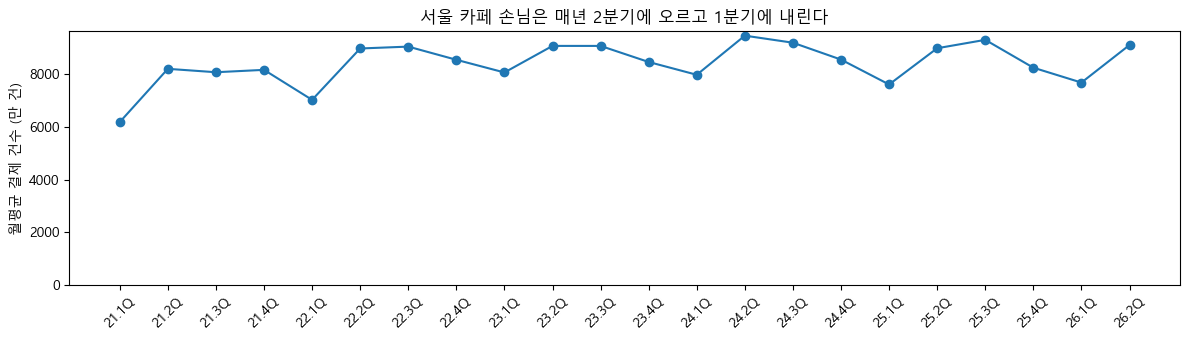

In [14]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot([quarter_label(q) for q in seoul_counts.index], seoul_counts["건수(만 건)"], marker="o")
ax.set_ylim(bottom=0)
ax.set_ylabel("월평균 결제 건수 (만 건)")
ax.set_title("서울 카페 손님은 매년 2분기에 오르고 1분기에 내린다")
ax.tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.show()

### 관찰
- 분기별 전 분기 대비 중앙값: 1분기 −6.8%, 2분기 +18.6%, 3분기 0.0%, 4분기 −6.7%
- 바로 앞 분기와 비교하면 계절 효과를 상권 변화로 잘못 읽게 됨 → 이후 지표는 4개 분기 합계끼리 또는 전년 같은 분기끼리 비교

## 5. 상권별 데이터 단절

- 상권 단위로는 계절 효과보다 훨씬 큰 분기 변화가 있는지 확인
- 기준: 전 분기 대비 2배 초과 상승, 또는 절반 미만으로 하락

In [15]:
qoq_change = quarterly_counts.pct_change(axis=1, fill_method=None).iloc[:, 1:]  # 첫 분기는 비교 대상 없음

pd.DataFrame({
    "2배 넘게 뜀": (qoq_change > JUMP_RATIO).sum(),
    "절반 아래로 떨어짐": (qoq_change < DROP_RATIO).sum(),
}).T

기준_년분기_코드,20212,20213,20214,20221,20222,20223,20224,20231,20232,20233,...,20241,20242,20243,20244,20251,20252,20253,20254,20261,20262
2배 넘게 뜀,52,27,14,12,44,27,14,22,41,21,...,23,37,14,8,12,26,21,10,12,26
절반 아래로 떨어짐,5,11,17,26,13,19,15,28,8,16,...,16,10,27,22,26,11,20,11,14,15


### 관찰
- 2배 넘게 뛴 상권이 매 분기 존재: 2021년 2분기 52곳, 2022년 2분기 44곳, 2026년 2분기 26곳 (출력된 분기 중 최소 8곳)
- 절반 아래로 떨어진 상권도 출력된 분기마다 5~28곳
- 서울 전체 계절 효과(2분기 +18.6%)로 설명되지 않는 크기 → 추계 방식 변화나 데이터 단절로 판단

In [16]:
start, end = BREAK_EXAMPLE_QUARTERS
print(raw_area.set_index("상권_코드").at[BREAK_EXAMPLE_CODE, "상권_코드_명"])
(quarterly_counts.loc[BREAK_EXAMPLE_CODE, start:end] / 1e4).round(1)

사당역 4번


기준_년분기_코드
20231     2.1
20232     2.1
20233     2.1
20234     1.8
20241     9.9
20242    11.7
20243    11.7
20244    10.3
Name: 3110902, dtype: float64

### 관찰
- 사당역 4번: 2023년 4분기 1.8만 건 → 2024년 1분기 9.9만 건, 한 분기 만에 5.5배
- 이후 2024년 내내 9.9만~11.7만 건 유지 (2023년은 1.8만~2.1만 건) → 실제 손님 변화보다 데이터 단절로 판단
- 이런 상권은 2년 증가율이 부풀려짐 → 추천에서 최근 12개 분기 안에 단절이 있는 상권 제외 (`docs/지표_정의서.md`)

## 6. 전처리에서 고칠 것

- 이름·컬럼명·타입 문제를 건수로 확인하고 `02_전처리`에서 처리할 목록 정리

In [17]:
n_area_name_broken = raw_area["상권_코드_명"].str.contains("?", regex=False).sum()
n_dong_name_broken = raw_area["행정동_코드_명"].str.contains("?", regex=False).sum()
n_multi_name_codes = (raw_sales.groupby("상권_코드")["상권_코드_명"].nunique() > 1).sum()
broken_time_cols = [col for col in raw_sales.columns if col.startswith("시간대_건수")]

print("상권 이름에 '?'가 들어간 행(영역):", int(n_area_name_broken))
print("행정동 이름에 '?'가 들어간 행(영역):", int(n_dong_name_broken))
print("이름이 2개 이상인 상권 코드(매출):", int(n_multi_name_codes))
print("깨진 시간대 건수 열 이름:", broken_time_cols)
print("실수형으로 읽힌 금액 열:", len(cafe_sales.select_dtypes("float").columns))

상권 이름에 '?'가 들어간 행(영역): 1
행정동 이름에 '?'가 들어간 행(영역): 38
이름이 2개 이상인 상권 코드(매출): 3
깨진 시간대 건수 열 이름: ['시간대_건수~06_매출_건수', '시간대_건수~11_매출_건수', '시간대_건수~14_매출_건수', '시간대_건수~17_매출_건수', '시간대_건수~21_매출_건수', '시간대_건수~24_매출_건수']
실수형으로 읽힌 금액 열: 22


### 관찰
- 상권 이름 `?` 1건, 행정동 이름 `?` 38건, 이름이 2개인 상권 코드 3개, 깨진 시간대 건수 컬럼 6개, float 금액 컬럼 22개

| 문제 | 처리 방법 |
|---|---|
| 가운뎃점(·)이 `?`로 깨짐 (예: `종로?청계 관광특구`) | `?`를 `·`로 변경. 같은 상권의 이전 연도 이름이 `종로·청계`라서 가운뎃점으로 판단 |
| 상권 코드 하나에 이름 2개 | 이름은 영역 테이블 기준으로 통일, 테이블 연결은 코드로 함 |
| 시간대별 건수 컬럼명 6개가 `시간대_건수~06_매출_건수`처럼 깨짐 | 금액 컬럼 규칙(`시간대_00~06_매출_건수`)으로 변경 |
| 점포 컬럼명이 2025년부터 바뀜 | 새 이름(`전체_점포_수`, `일반_점포_수`)으로 통일 |
| 금액 컬럼 일부가 float | 소수 부분이 모두 0이면 int로 변환. 21억 초과 값이 있어 SQL에서는 `BIGINT` 필요 |
| 다른 업종 | 커피-음료(`CS100010`)만 남김 |

## 결론과 다음 단계

- 분석 대상: 커피-음료 업종, 2021년 1분기 ~ 2026년 2분기 22개 분기
- 매출은 카페 3개 이상 상권만 공개 → 매출이 공개된 상권 안에서만 추천 가능
- 2분기 상승·1분기 하락의 계절성 확인 → 4개 분기 합계 또는 전년 같은 분기끼리 비교
- 한 분기 2배 초과 변화 상권 매 분기 존재 → 추천에서 단절 상권 제외
- 다음 단계: 6절 목록을 `02_전처리.ipynb`에서 처리